In [1]:
# Previously, we took one character and predicted the next character based on the prob. distribution of next characters. 
# If we were to take more context (consider more characters before predicting the next character), 
# our matrix of frequencies (the N matrix) would grow exponentially. (take 2 chars -> # of rows = 27*27)

In [3]:
# MLP approach (from Bengio et al 2003):
# predicts a word given previous 3 words in a sentence. 
# in this implementation we take 3 letter characters as trigrams (context blocks) and predict the next letter character after it. 

# forward pass:
# 1. embed each letter character in vocab into a feature vector with 2 dimensions. (may or may not be enough for 27 characters)
# 2. a 27 by 2 lookup matrix is generated and constructed. it contains 2d coords of all 27 characters. 
# 3. training:
# - build tensor with all trigrams X (X.shape = [228146, 3]) and tensor with all characters after respective trigrams Y from the dataset. 
# - embedded matrix (emb.shape = [228146, 3, 2]) is built, it contains all trigrams and their embedded coords in 2d
# - 1 hidden layer of 100 neurons accept 6 inputs (3 sets of embedded coords of each trigram) each
# - W1 ([6, 100]), biases b1 (100) and tanh activation function work on emb, which is now viewed with shape [228146, 6]
# - which outputs matrix of outputs h ([228146, 100]). 100 neuron works on the ith trigram and outputs 100 outputs per trigram
# - combine outputs using a softmax layer with W2 ([100, 27]) and b2 (27).
# - call softmax on logits ([228146, 27]) to determine pds of the next character after each trigram
# - calculate nll using Y. 

# backward pass:
# - backward propagation uses grad to shift word coords adhering training sentences.
#   e.g. move coords so "cat" is a more likely next prediction after "the"
# - backprop moves "dog" closer to "cat" as they both should predict "walked" next. 
#   as a result it is more likely to predict either of them after "the" too.

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [4]:
# open 'words.txt' as a python list of all the words
words = open('names.txt', 'r').read().splitlines()
len(words) # number of words in our vocabulary

32033

In [5]:
# convert letter characters into integer tokens and back
chars = sorted(list(set(''.join(words)))) # sorted alphabet
stoi = {s:i + 1 for i, s in enumerate(chars)} # iterate over alphabet to index them
stoi['.'] = 0 # index = 0, shift every letter in stoi by 1
itos = {i:s for s,i in stoi.items()} # create an inverse dictionary of stoi

In [6]:
# one forward pass

In [7]:
# weights and biases for the two layers
W1 = torch.randn(6, 100)
b1 = torch.randn(100)
W2 = torch.randn(100, 27)
b2 = torch.randn(27)

C = torch.randn([27, 2]) # 27 by 2 table

In [8]:
# set up parameters
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

# this needs to be ran after defining C, W1, b1, W2 and b2 but BEFORE the first pass!

In [9]:
# build the dataset
# instead of bigrams we will use trigrams

block_size = 3 # context length

def build_dataset(words):
    X, Y = [], [] # inputs and target prediction output lists (soon to be tensors)
    for w in words:
        context = [0] * block_size # zero row vector of length = block_size
        for ch in w + '.': # separate each word with '.'
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(context, '--->', ix, f'({itos[ix]})') # demonstrate context to predicted output
            context = context[1:] + [ix] # omit context[0] (first element) and append new index ix to end of cropped context list
      
    X = torch.tensor(X)
    Y = torch.tensor(Y)

    return X, Y

X, Y = build_dataset(words)
print(X.shape)
print(Y.shape)

torch.Size([228146, 3])
torch.Size([228146])


In [10]:
# build lookup table C
# since we have 27 possible characters (instd of 17000 words) we can try a 2D space
# side note: one-hot row vector from bigram model * C outputs embedded coordinates. 
# embedded coordinates consists of 2 random floats and dictates a letter's position in the 2D space. 

emb = C[X] # pytorch replaces each ix with corresponding embedded coordinate
print(emb.shape)
print(emb)
# our nn evaluates 228146 (all) trigram context blocks at the same time

torch.Size([228146, 3, 2])
tensor([[[ 0.1245, -0.8347],
         [ 0.1245, -0.8347],
         [ 0.1245, -0.8347]],

        [[ 0.1245, -0.8347],
         [ 0.1245, -0.8347],
         [ 0.6715, -1.5344]],

        [[ 0.1245, -0.8347],
         [ 0.6715, -1.5344],
         [-0.3981, -1.1238]],

        ...,

        [[ 0.3240, -0.8017],
         [ 0.3240, -0.8017],
         [ 0.2915, -1.2189]],

        [[ 0.3240, -0.8017],
         [ 0.2915, -1.2189],
         [ 0.3240, -0.8017]],

        [[ 0.2915, -1.2189],
         [ 0.3240, -0.8017],
         [-0.6777, -0.8322]]], grad_fn=<IndexBackward0>)


In [11]:
# hidden layer: 
# propose 100 neurons in a single layer
# each neuron takes 6 inputs (3 sets of 2d coords)
# 100 neurons receive the same neuron and outputs a row of 100 outputs/activation values
# 32 instances of trigram evaluation happens at the same time
# e.g. row one for evaluating ..., row two for evaluating ..e, row three for .em, ...

In [12]:
# construct hidden layer
print(f"""emb shape: {emb.shape}""")
print(f"""W1 shape: {W1.shape}""")

# concatenate emb such that each [3, 2] set of coords turns into [6] 6 inputs 
# else emb @ W1 is invalid
# torch.cat creates new tensors with new storage taking up memory - less efficient than viewing each [3, 2] as [6]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # -1 infers # of rows based on # of columns and # of elements in emb (228146 * 3 * 2)
print(f"""concatenated emb shape: {emb.view(-1, 6).shape}""") # should be [32, 6] instead of [32, 3, 2]

emb shape: torch.Size([228146, 3, 2])
W1 shape: torch.Size([6, 100])
concatenated emb shape: torch.Size([228146, 6])


In [13]:
print(h.shape)
h

torch.Size([228146, 100])


tensor([[ 0.8239,  0.1418,  0.6169,  ...,  0.9987,  0.5738, -0.2145],
        [ 0.9384, -0.2317,  0.4566,  ...,  0.9975,  0.5786, -0.8130],
        [ 0.9889,  0.9242,  0.6820,  ...,  0.9998,  0.9311,  0.5999],
        ...,
        [ 0.8883,  0.2574,  0.6090,  ...,  0.9989,  0.6349, -0.7384],
        [ 0.8899,  0.8103,  0.8170,  ...,  0.9996, -0.2997, -0.3251],
        [ 0.9143,  0.4052,  0.7408,  ...,  0.9993,  0.9165,  0.1416]],
       grad_fn=<TanhBackward0>)

In [14]:
# softmax layer:
# pass through INDEPENDENT outputs of the hidden layer to generate probability densities of the next letter character. 
# softmax takes unnormalised raw logits and output probabilities adding up to 1. 
# if use softmax as hidden layer activation function, 100 neuron outputs would compete and diminish fire rates. 

# softmax(xi) = e^xi/(sum(e^xj)), over total exponentiated sum. 
# negative xi become positive after exp, and high x stand out tremendously. 

In [15]:
logits = h @ W2 + b2

In [16]:
# applying softmax
counts = logits.exp()
prob = counts/counts.sum(1, keepdims=True)
print(prob.shape)
# each row represent one trigram context block
# 27 columns contains 27 probabilities for the next character after the trigram
# prob[i, j] is probability of character j after trigram at the ith row

torch.Size([228146, 27])


In [17]:
# calculate mean nll loss
# require grad = True BEFORE calculating loss
loss = -prob[torch.arange(228146), Y].log().mean()
loss
# prob[torch.arange(228146), Y] evaluates probability of Y[i] after ith trigram,
# throughout all 228146 trigram -> next character training data. 

tensor(19.9653, grad_fn=<NegBackward0>)

In [18]:
# or use F.cross_entropy to calculate nll
loss = F.cross_entropy(logits, Y)
loss
# this implementation does not create tensors such as counts, prob etc. its more efficient

tensor(19.9653, grad_fn=<NllLossBackward0>)

In [19]:
# backward pass

In [20]:
# set parameter (C, W1, W2, b1, b2) gradients to be 0
p_sum = sum(p.nelement() for p in parameters)
for p in parameters:
    p.grad = None 
loss.backward()
for p in parameters:
    p.data += -0.1 * p.grad # important! negative!!

In [28]:
# ===cleanly implement forward and backward passes===

In [283]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [284]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [285]:
# open 'words.txt' as a python list of all the words
words = open('names.txt', 'r').read().splitlines()
len(words) # number of words in our vocabulary

32033

In [286]:
# convert letter characters into integer tokens and back
chars = sorted(list(set(''.join(words)))) # sorted alphabet
stoi = {s:i + 1 for i, s in enumerate(chars)} # iterate over alphabet to index them
stoi['.'] = 0 # index = 0, shift every letter in stoi by 1
itos = {i:s for s,i in stoi.items()} # create an inverse dictionary of stoi

In [298]:
block_size = 3 # context length

def build_dataset(words):
    X, Y = [], [] # inputs and target prediction output lists (soon to be tensors)
    for w in words:
        context = [0] * block_size # zero row vector of length = block_size
        for ch in w + '.': # separate each word with '.'
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(context, '--->', ix, f'({itos[ix]})') # demonstrate context to predicted output
            context = context[1:] + [ix] # omit context[0] (first element) and append new index ix to end of cropped context list
      
    X = torch.tensor(X)
    Y = torch.tensor(Y)

    return X, Y

import random
random.shuffle(words)
n1 = int(0.8*len(words)) # 80% of shuffled words
n2 = int(0.9*len(words)) # 90%

# build training, dev and testing datasets (80%, 10% and 10%)
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# training split - 80% of all training, optimise params
# validation split - 10%, development of hyperparams 
# (e.g. size of hidden layer, dimensions of embed coords)
# test split - 10%, evaluate performance of model

In [288]:
print(n1, n2, n2 - n1) # should be 0.8, 0.1 and 0.1 * 32k

25626 28829 3203


In [289]:
# setting up parameters
# what are character embedding dimension and number of neuron in hidden layer bottlenecks??

C = torch.randn((27, 2))
# too few dimensions may cause crowding - what are supposed to be weak relationships are amplified

W1 = torch.randn(6, 300) # 100 -> 300 neurons, each with 6 random weights
# increasing number of neurons in hidden layer decreases converged loss, but takes more training to get there
# too few neurons result in a high converged loss

b1 = torch.randn(300)
W2 = torch.randn(300, 27)
b2 = torch.randn(27)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

In [290]:
# try learning rates between low and high bounds
lre = torch.linspace(-3, 0, 10000) # learning_rate_exponent
lrs = 10**lre # learning rates we want to cycle through
# lrs is 0.001 to 1 - but not linear

In [291]:
lri = []
lossi = []
stepi = []

# training split
# we first determine optimal learning rate
for i in range(10000):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (32,)) # batches of 32 random ixs
    
    # fwd pass
    emb = C[Xtr[ix]] # only embed ix, (32, 3, 2) 
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) 
    logits = logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    # bwd pass
    for p in parameters:
        p.grad = None 
    loss.backward()
    # loss.backward() is inconsistent (has small increasing jumps) as each batch is a different subset of all data
    # for p in parameters:
    #     p.data += -0.1 * p.grad # 0.1 learning rate is just a guess
    
    # parsing through different learning rates
    lr = lrs[i] #use this + track stats and plot lossi against lri to determine optimal lr range. 
    for p in parameters:
        p.data += -lr * p.grad
    
    # track stats
    lri.append(lre[i])
    #stepi.append(i)
    lossi.append(loss.item())
print(f"loss after learning rate training: {loss.item()}")

loss after learning rate training: 15.8951416015625


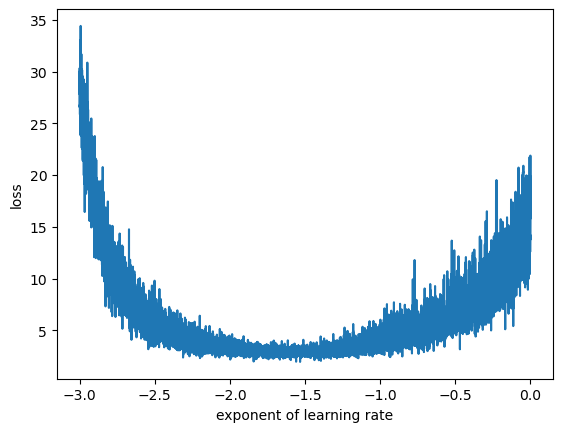

In [292]:
plt.close('all')
plt.plot(lri, lossi)
plt.xlabel('exponent of learning rate')
plt.ylabel('loss')
plt.show()

In [293]:
# now we know that 10**-1.5 should be good enough, we use that
lossi = []

for i in range(10000):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (32,)) # batches of 32 random ixs
    
    # fwd pass
    emb = C[Xtr[ix]] # only embed ix, (32, 3, 2) 
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) 
    logits = logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    # bwd pass
    for p in parameters:
        p.grad = None 
    loss.backward()
    
    lr = 10**-1.5 if i < 10001 else 0.01 # use decay learn rate when loss plateaus.
    for p in parameters:
        p.data += -lr * p.grad
    
    # track stats
    stepi.append(i)
    lossi.append(loss.item())
print(f"loss after more training: {loss.item()}")

loss after more training: 2.465883731842041


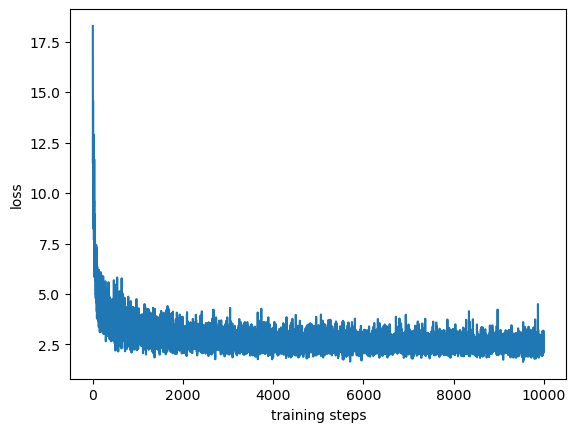

In [294]:
plt.close('all')
plt.plot(stepi, lossi)
plt.xlabel('training steps')
plt.ylabel('loss')
plt.show()

In [297]:
# minibatch loss isnt whole data loss
# small minibatch causes loss vs steps graph to be noisy too
# validation split:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) 
logits = logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
print(f"loss of validation split: {loss}")

loss of validation split: 2.487389326095581


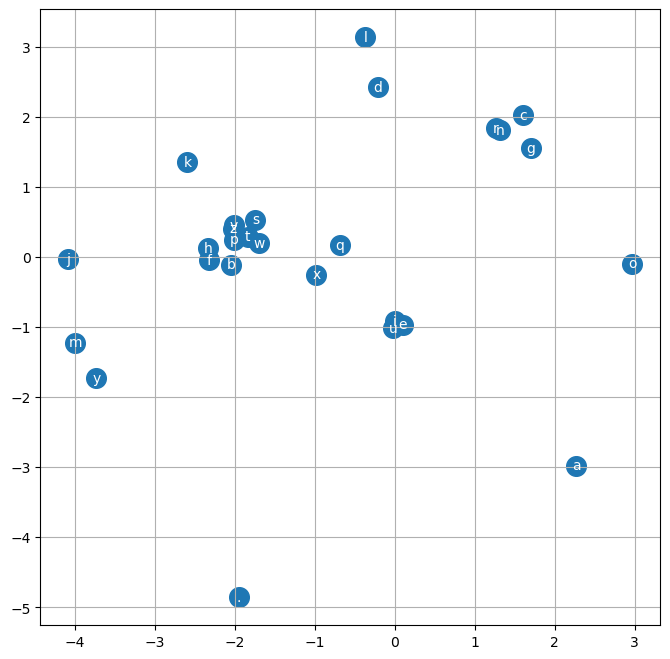

In [301]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.close('all')
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')
plt.show()

In [8]:
# 2d might be bottleneck - try 10d
# no need to rewrite all code, just modify above
# above and below are for demonstration and comparison purposes

In [302]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [304]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()

In [306]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [307]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [310]:
# generate parameters
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g) # 200 instead of 300 neurons
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [311]:
lri = []
lossi = []
stepi = []

In [323]:
for i in range(100000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # 30 instead of 6
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100001 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

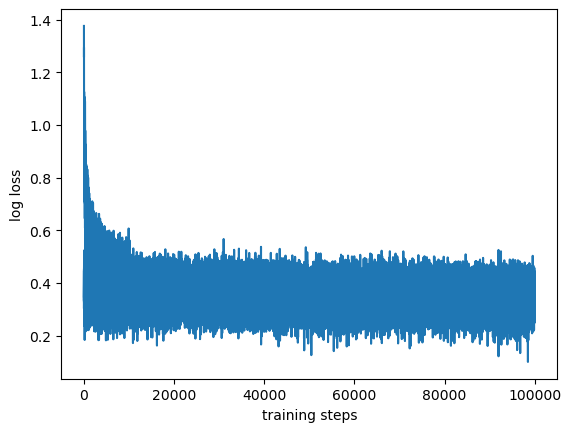

In [324]:
plt.close('all')
plt.plot(stepi, lossi)
plt.xlabel('training steps')
plt.ylabel('log loss')
plt.show()

In [329]:
# training set loss
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
print(f"training set loss: {loss}")

training set loss: 2.242302656173706


In [330]:
# dev set loss
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
print(f"dev set loss: {loss}")

dev set loss: 2.2878973484039307


In [ ]:
# repeat above until we beat 2.32 (digram)
# dev set loss > training set loss -> overfit (a little bit)

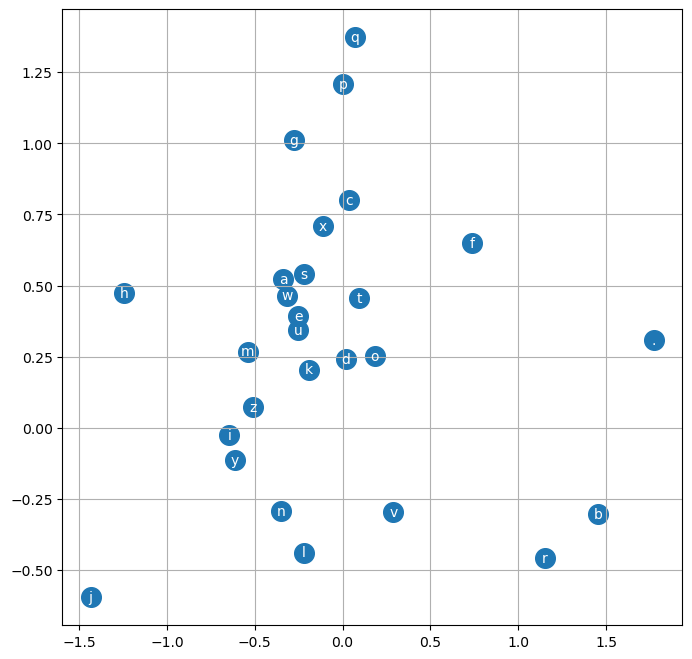

In [328]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.close('all')
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')
plt.show()

In [332]:
# now generate some names

for _ in range(20):
    
    out = []
    context = [0] * block_size
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(f"name generated: {''.join(itos[i] for i in out)}")


name generated: zeooluwa.
name generated: lapp.
name generated: mariea.
name generated: taviany.
name generated: jaleya.
name generated: daynielayo.
name generated: prayne.
name generated: jan.
name generated: afen.
name generated: jaxs.
name generated: bob.
name generated: kayah.
name generated: aveyair.
name generated: atami.
name generated: zaynest.
name generated: rafer.
name generated: robbia.
name generated: amair.
name generated: yain.
name generated: jaylee.
